# 01 — Exploratory data analysis: UCI Bank Marketing (`bank-full`)

**CallWise · EC-417 P05 · Roll Nos. 623169 & 623195**

Goal of this notebook: understand the data before any modelling.
1. Size, types and class balance (why accuracy is misleading)
2. Where the "missing" values hide (`unknown`, `pdays = -1`)
3. Numeric distributions
4. **The famous leak:** `duration`
5. Subscription rate by month, job, previous outcome and contact type

This notebook is descriptive only. No model, encoder or threshold is fitted here,
so looking at the whole file does not leak anything into the test set.
The leak-free split is created in `src/data.py` (Phase 2).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score
from src import plotstyle as ps

ps.apply()
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)

## 1. Load and check

In [2]:
df = pd.read_csv(ROOT / "data" / "raw" / "bank-full.csv", sep=";")
assert df.shape == (45211, 17), df.shape
print(df.shape, "| empty cells:", df.isna().sum().sum())
df.head()

(45211, 17) | empty cells: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.dtypes.to_frame("dtype").T

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
dtype,int64,str,str,str,str,int64,str,str,str,int64,str,int64,int64,int64,int64,str,str


## 2. Class balance (figure F1)
Only about 1 in 9 clients subscribes. A model that always says "no" is right 88.3% of the time,
so **accuracy is not a useful metric here**. We use PR-AUC, whose no-skill value equals the positive rate.

     count  share
y                
no   39922  0.883
yes   5289  0.117

Always-'no' accuracy: 0.883   |   no-skill PR-AUC = positive rate = 0.117


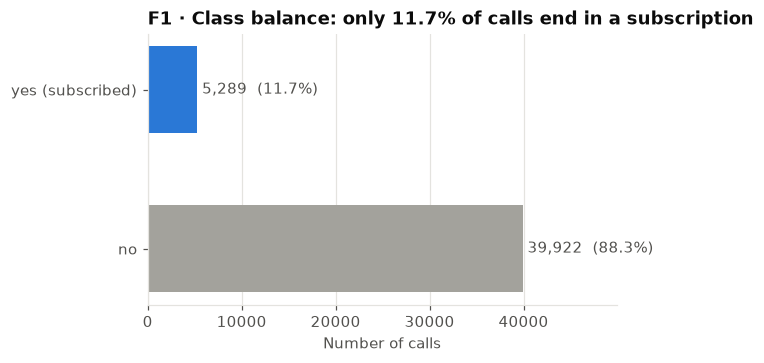

In [4]:
counts = df["y"].value_counts().reindex(["no", "yes"])
share = counts / counts.sum()
print(pd.DataFrame({"count": counts, "share": share.round(4)}))
print(f"\nAlways-'no' accuracy: {share['no']:.3f}   |   no-skill PR-AUC = positive rate = {share['yes']:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.barh(["yes (subscribed)", "no"][::-1], counts.values, color=[ps.NO_COLOR, ps.YES_COLOR],
               height=0.55)
for b, n, s in zip(bars, counts.values, share.values):
    ax.text(b.get_width() + 500, b.get_y() + b.get_height() / 2, f"{n:,}  ({s:.1%})",
            va="center", color=ps.INK_2)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Number of calls")
ax.grid(axis="y", visible=False)
ax.set_title("F1 · Class balance: only 11.7% of calls end in a subscription")
fig.savefig(FIG / "F1_class_balance.png")
plt.show()

## 3. Hidden missing values
There are no empty cells, but missing information is coded in two ways:
* the string `"unknown"` in categorical columns;
* `pdays = -1`, meaning the client was **never contacted** in a previous campaign.

In [5]:
cats = df.select_dtypes(exclude="number").columns.drop("y")
unk = pd.DataFrame({
    "levels": [df[c].nunique() for c in cats],
    "unknown": [(df[c] == "unknown").sum() for c in cats],
}, index=cats)
unk["unknown_%"] = (100 * unk["unknown"] / len(df)).round(1)
print(unk)
never = (df["pdays"] == -1).sum()
print(f"\npdays == -1 (never contacted before): {never:,} rows ({never/len(df):.1%})")
print("poutcome == 'unknown' :", (df['poutcome'] == 'unknown').sum())
print("rows with pdays == -1 AND poutcome == 'unknown':",
      ((df['pdays'] == -1) & (df['poutcome'] == 'unknown')).sum())

           levels  unknown  unknown_%
job            12      288        0.6
marital         3        0        0.0
education       4     1857        4.1
default         2        0        0.0
housing         2        0        0.0
loan            2        0        0.0
contact         3    13020       28.8
month          12        0        0.0
poutcome        4    36959       81.7

pdays == -1 (never contacted before): 36,954 rows (81.7%)
poutcome == 'unknown' : 36959
rows with pdays == -1 AND poutcome == 'unknown': 36954


**Decisions (documented in `data/README.md`):**
* `unknown` stays as its own category. It is informative (e.g. `contact = unknown` is concentrated in
  May–June: 12,507 of its 13,020 rows, and these clients subscribe at only 4%), so imputing it would throw signal away.
* `pdays` stays as-is (trees can split on -1) and we add a flag `previously_contacted = (pdays != -1)`.
* `poutcome = unknown` is almost exactly the "never contacted" group, so it is not really missing data.

In [6]:
# contact = unknown is concentrated in a few months
pd.crosstab(df["month"], df["contact"]).reindex(
    ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"])

contact,cellular,telephone,unknown
month,,,
jan,1265,129,9
feb,2362,274,13
mar,417,53,7
apr,2727,199,6
may,5331,460,7975
jun,729,80,4532
jul,5767,852,276
aug,5950,246,51
sep,466,66,47


## 4. Numeric distributions

In [7]:
nums = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
df[nums].describe(percentiles=[.25, .5, .75, .99]).T.round(1)

,count,mean,std,min,25%,50%,75%,99%,max
age,45211.0,40.9,10.6,18.0,33.0,39.0,48.0,71.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,13164.9,102127.0
day,45211.0,15.8,8.3,1.0,8.0,16.0,21.0,31.0,31.0
duration,45211.0,258.2,257.5,0.0,103.0,180.0,319.0,1269.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,3.0,16.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,370.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,8.9,275.0


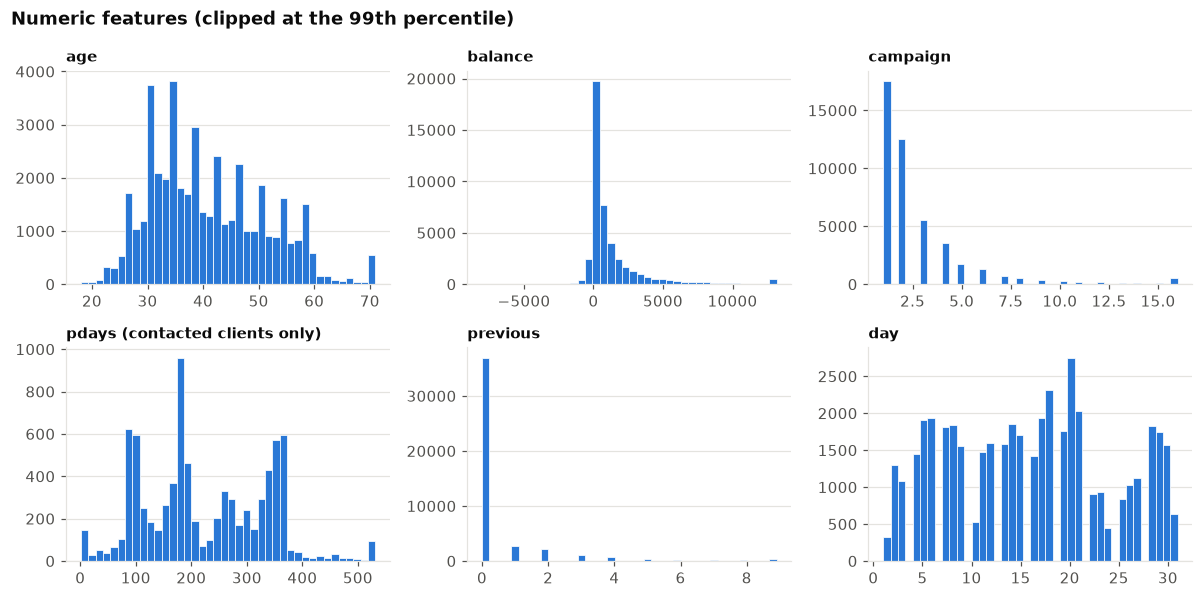

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.ravel(), ["age", "balance", "campaign", "pdays", "previous", "day"]):
    x = df[col]
    if col == "pdays":
        x = x[x != -1]  # -1 = never contacted, shown separately above
    hi = x.quantile(0.99)
    ax.hist(x.clip(upper=hi), bins=40, color=ps.SERIES[0], edgecolor="white", linewidth=0.5)
    ax.set_title(col + (" (contacted clients only)" if col == "pdays" else ""), fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Numeric features (clipped at the 99th percentile)", x=0.01, ha="left",
             fontweight="bold", color=ps.INK)
fig.tight_layout()
fig.savefig(FIG / "EDA_numeric_distributions.png")
plt.show()

`balance`, `campaign`, `previous` and `pdays` are heavily right-skewed. Tree models do not care about
scale or skew (they only use the order of values), so no scaling or log transform is needed.

## 5. The famous leak: `duration` (figure F2, part 1)
`duration` is the length of the call in seconds. It is only known **after** the call ends,
so it cannot be used to decide *whom to call*. It is also very predictive:
long calls are calls where the client was interested.

In [9]:
print(df.groupby("y")["duration"].describe()[["count", "25%", "50%", "75%", "mean"]].round(0))
print("\nCalls with duration == 0:", (df["duration"] == 0).sum(),
      "-> outcomes:", df.loc[df["duration"] == 0, "y"].tolist())

y01 = (df["y"] == "yes").astype(int)
ap_dur = average_precision_score(y01, df["duration"])
roc_dur = roc_auc_score(y01, df["duration"])
print(f"\nRanking clients by duration alone (no model at all):")
print(f"  PR-AUC = {ap_dur:.3f}  (no-skill = {y01.mean():.3f})   ROC-AUC = {roc_dur:.3f}")

       count    25%    50%    75%   mean
y                                       
no   39922.0   95.0  164.0  279.0  221.0
yes   5289.0  244.0  426.0  725.0  537.0

Calls with duration == 0: 3 -> outcomes: ['no', 'no', 'no']

Ranking clients by duration alone (no model at all):
  PR-AUC = 0.386  (no-skill = 0.117)   ROC-AUC = 0.808


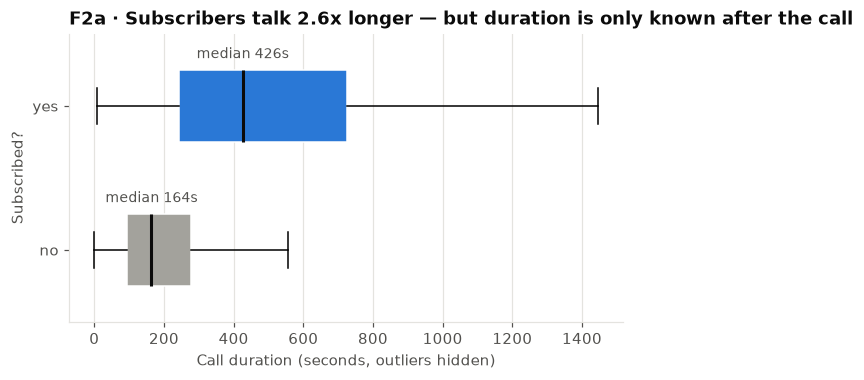

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
data = [df.loc[df.y == "no", "duration"], df.loc[df.y == "yes", "duration"]]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=["no", "yes"], widths=0.5, patch_artist=True,
                showfliers=False, medianprops=dict(color=ps.INK, linewidth=2))
for patch, c in zip(bp["boxes"], [ps.NO_COLOR, ps.YES_COLOR]):
    patch.set_facecolor(c); patch.set_edgecolor("white")
for i, d in enumerate(data, start=1):
    ax.text(d.median(), i + 0.33, f"median {d.median():.0f}s", ha="center", color=ps.INK_2, fontsize=9)
ax.set_xlabel("Call duration (seconds, outliers hidden)")
ax.set_ylabel("Subscribed?")
ax.grid(axis="y", visible=False)
ax.set_title(f"F2a · Subscribers talk 2.6x longer — but duration is only known after the call")
fig.savefig(FIG / "F2a_duration_by_y.png")
plt.show()

**Takeaway.** Sorting clients by `duration` alone, with no model, already gives a PR-AUC far above the
0.117 baseline. Any model that sees `duration` will look excellent but is useless before the call.
So every model is trained on two feature sets:

| Set | Columns | Use |
|---|---|---|
| FULL | all 16 features incl. `duration` | reference only, to measure the leak |
| DEPLOYABLE | 15 features (no `duration`) + `previously_contacted` | headline results |

Part 2 of figure F2 (model PR-AUC with vs without `duration`) is produced after training (Phase 3).

## 6. Subscription rate by group

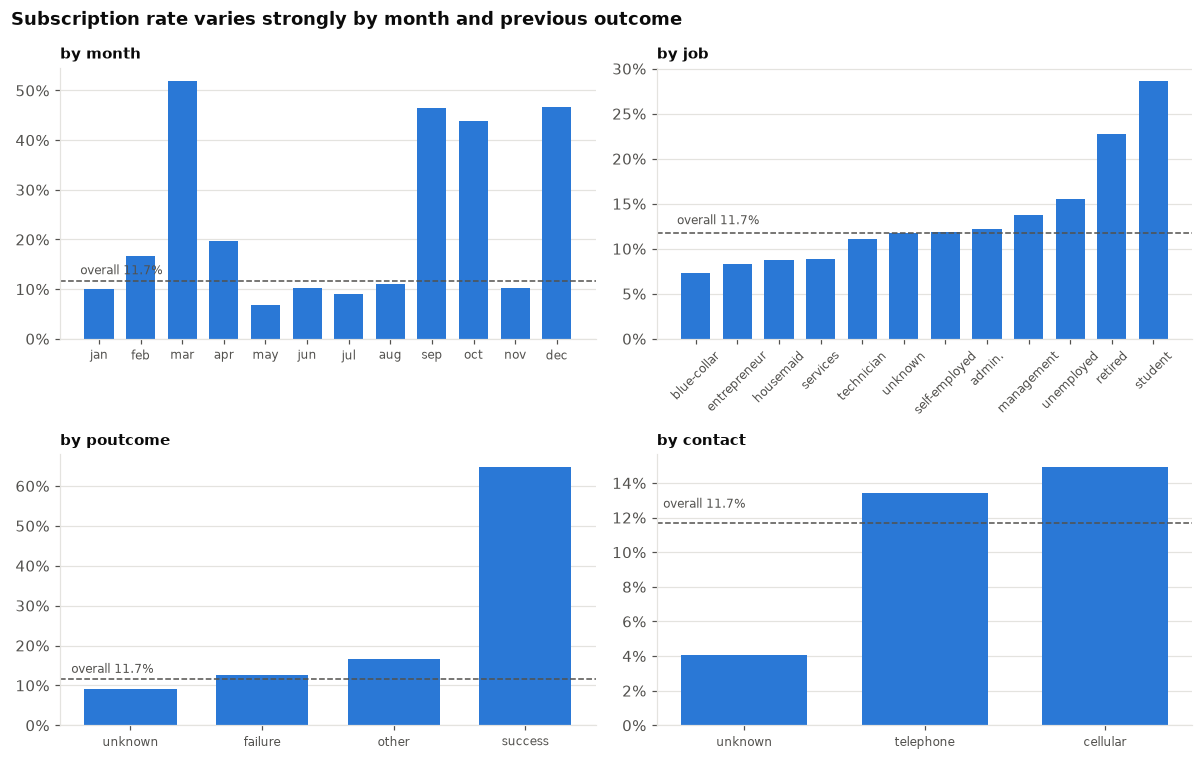

In [11]:
def rate(col, order=None):
    r = df.groupby(col)["y"].agg(rate=lambda s: (s == "yes").mean(), n="size")
    return r.reindex(order) if order else r.sort_values("rate")

MONTHS = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, order) in zip(axes.ravel(), [("month", MONTHS), ("job", None),
                                           ("poutcome", None), ("contact", None)]):
    r = rate(col, order)
    ax.bar(r.index, r["rate"], color=ps.SERIES[0], width=0.7)
    ax.axhline(y01.mean(), color=ps.INK_2, linestyle="--", linewidth=1)
    ax.text(-0.45, y01.mean() * 1.06, "overall 11.7%", ha="left", va="bottom", color=ps.INK_2, fontsize=8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.set_title(f"by {col}", fontsize=10)
    ax.tick_params(axis="x", rotation=45 if col == "job" else 0, labelsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Subscription rate varies strongly by month and previous outcome",
             x=0.01, ha="left", fontweight="bold", color=ps.INK)
fig.tight_layout()
fig.savefig(FIG / "EDA_rate_by_group.png")
plt.show()

In [12]:
for col in ["poutcome", "contact"]:
    print(rate(col).assign(rate=lambda t: t.rate.round(3)), "\n")
print(rate("month", MONTHS).assign(rate=lambda t: t.rate.round(3)).T)

           rate      n
poutcome              
unknown   0.092  36959
failure   0.126   4901
other     0.167   1840
success   0.647   1511 

            rate      n
contact                
unknown    0.041  13020
telephone  0.134   2906
cellular   0.149  29285 

month       jan       feb     mar       apr        may       jun       jul      aug      sep      oct       nov  \
rate      0.101     0.166    0.52     0.197      0.067     0.102     0.091     0.11    0.465    0.438     0.102   
n      1403.000  2649.000  477.00  2932.000  13766.000  5341.000  6895.000  6247.00  579.000  738.000  3970.000   

month      dec  
rate     0.467  
n      214.000  


## 7. Summary of findings
* **45,211 calls, 16 features, 11.70% "yes".** Accuracy is misleading (88.3% for "always no");
  the primary metric is **PR-AUC** (no-skill = 0.117), with ROC-AUC as secondary.
* **Missing data is hidden** as `"unknown"` (contact 29%, poutcome 82%, education 4%, job 0.6%) and
  `pdays = -1` (82% never contacted). We keep `"unknown"` as a category and add `previously_contacted`.
* **`duration` is a leak:** subscribers' median call is 426 s vs 164 s; ranking by duration alone already gives
  a high PR-AUC. It is excluded from the deployable model.
* **Strong pre-call signals exist:** previous campaign success (≈65% subscribe), months with few calls
  (mar, sep, oct, dec ≈ 44–52%), cellular contact, students and retirees. These are what the
  deployable model has to work with.
* Numeric features are skewed, but tree models are scale-free, so no transforms are needed.